In [1]:
#importe das bibliotecas utilizadas

import cv2
import numpy as np
import matplotlib.pyplot as plt
import time
import tracemalloc


In [ ]:
# Processamento de imagem usando OpenCV
# Bruno Vanjura Vieira


def pegar_informacoes(caminho):
    # Abre o arquivo de vídeo a partir do caminho informado
    video = cv2.VideoCapture(caminho)

    # Lê taxa de quadros por segundo (FPS) e quantidade total de quadros
    fps = video.get(cv2.CAP_PROP_FPS)
    total_frames = video.get(cv2.CAP_PROP_FRAME_COUNT)

    # Calcula a duração estimada do vídeo em segundos
    duracao = total_frames / fps

    # Lê largura e altura originais dos quadros e converte contagens para inteiro
    largura = int(video.get(cv2.CAP_PROP_FRAME_WIDTH))
    altura = int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total_frames = int(video.get(cv2.CAP_PROP_FRAME_COUNT))

    # Calcula o total de pixels de um único quadro e do vídeo inteiro
    pixels_por_frame = largura * altura
    total_pixels_video = pixels_por_frame * total_frames

    # Exibe as métricas e dimensões do vídeo no console
    print("FPS:", fps)
    print("Duração:", duracao, "segundos")

    print(f"Resolução: {largura}x{altura}")
    print(f"Pixels por quadro: {pixels_por_frame}")
    print(f"Total de quadros: {total_frames}")
    print(f"Total de pixels no vídeo: {total_pixels_video}")

    # Libera o recurso do vídeo após a leitura
    video.release()


# Função para montar a matriz M (cada coluna = um quadro vetorizado; cada linha = um pixel no tempo)
def obter_matriz_M(caminho_video, largura=160, altura=120):
    # Abre o vídeo para extração dos quadros
    video = cv2.VideoCapture(caminho_video)

    # Garante que o arquivo foi aberto corretamente antes de ler os quadros
    if not video.isOpened():
        raise Exception("Não foi possível abrir o vídeo!")

    # Lista que armazenará todos os quadros pré-processados
    frames = []

    # Percorre o vídeo quadro a quadro até o fim
    while True:
        ret, frame = video.read()

        # Interrompe o laço quando não há mais quadros (ret é False)
        if not ret:
            break

        # Converte o quadro de BGR (padrão OpenCV) para escala de cinza (1 canal de intensidade)
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

        # Redimensiona o quadro para a largura e altura desejadas
        gray = cv2.resize(gray, (largura, altura))

        # Guarda o quadro processado na lista
        frames.append(gray)

    # Libera o objeto de captura de vídeo
    video.release()

    # Verifica se ao menos um quadro foi extraído
    if len(frames) == 0:
        raise Exception("Nenhum quadro foi extraído!")

    # Transforma cada quadro 2D (altura x largura) em um vetor 1D de tamanho (largura * altura)
    vetores = [frame.flatten() for frame in frames]

    # Empilha os vetores como colunas para formar M:
    # - linhas = pixels (largura * altura)
    # - colunas = quadros (frames do vídeo)
    M = np.column_stack(vetores).astype(float)

    return M


# Gera a matriz M (19.200 linhas por total de quadros como colunas)
M = obter_matriz_M("data/caio_lutando.mp4")

# Imprime a matriz M resultante
print(M)

[[ 39.  34.  29. ...  64.  64.  64.]
 [ 60.  64.  63. ...  15.  15.  15.]
 [ 26.  25.  24. ...  74.  74.  74.]
 ...
 [ 97. 105. 105. ... 133. 133. 126.]
 [131. 133. 133. ... 110. 111. 109.]
 [135. 126. 126. ... 138. 137. 136.]]


In [15]:
'''Decomposicao SVD (versao corrigida)'''
'''Parte 2: Joao Pedro Gomes Araujo Munhoz Ribeiro'''

# SVD pelo metodo QR aplicado a matriz de Gram M.T @ M.
def DecomposicaoSVD(A, tol=1e-10, max_iter=5000, rel_cutoff=1e-8):
    A = np.asarray(A, dtype=float)
    if A.ndim != 2 or min(A.shape) == 0:
        raise ValueError("A deve ser uma matriz nao vazia.")
    inicio = time.perf_counter()
    m, n = A.shape
    G = A.T @ A
    G = 0.5 * (G + G.T)
    T = G.copy()
    V = np.eye(n)
    escala = max(np.linalg.norm(T, ord="fro"), 1.0)
    for _ in range(max_iter):
        if np.linalg.norm(T - np.diag(np.diag(T)), ord="fro") <= tol * escala:
            break
        Q, R = np.linalg.qr(T)
        T = R @ Q
        T = 0.5 * (T + T.T)
        V = V @ Q
    else:
        raise RuntimeError("A iteracao QR nao convergiu dentro do limite definido.")

    autovalores = np.diag(T).copy()
    ordem = np.argsort(autovalores)[::-1]
    autovalores = np.maximum(autovalores[ordem], 0.0)
    V = V[:, ordem]

    sigma = np.sqrt(autovalores)
    # Limiar mais conservador para evitar amplificar ruido numerico via A.T @ A
    limite = max(
        np.finfo(float).eps * max(m, n) * (sigma[0] if sigma.size else 0.0),
        rel_cutoff * (sigma[0] if sigma.size else 0.0),
    )
    posto = sigma > limite
    sigma = sigma[posto]
    V = V[:, posto]

    if sigma.size:
        U = (A @ V) / sigma[np.newaxis, :]
    else:
        U = np.empty((m, 0))

    return U, np.diag(sigma), V.T, time.perf_counter() - inicio



In [3]:
# Decomposicao SVD pelo metodo de Jacobi

# Calcula os coeficientes da rotacao que zera a entrada A[p, q].
def matriz_rotacao_jacobi(A, p, q):
    phi = (A[q, q] - A[p, p]) / (2.0 * A[p, q])
    if phi == 0:
        t = 1.0
    else:
        t = 1.0 / (phi + np.copysign(1.0, phi) * np.sqrt(phi**2 + 1.0))
    c = 1.0 / np.sqrt(1.0 + t**2)
    s = t * c
    return c, s


# Encontra o maior elemento fora da diagonal para verificar a convergencia.
def find_position(A):
    if A.shape[0] < 2:
        return 0, 0, 0.0
    fora_diagonal = np.triu(np.abs(A), k=1)
    p, q = np.unravel_index(np.argmax(fora_diagonal), fora_diagonal.shape)
    return p, q, fora_diagonal[p, q]


# Diagonaliza a matriz simetrica A e acumula seus autovetores nas colunas de V.
def solve_jacobi(A, tol=1e-12, max_sweeps=100):
    A = np.asarray(A, dtype=float)
    if A.ndim != 2 or A.shape[0] != A.shape[1] or A.shape[0] == 0:
        raise ValueError("A deve ser uma matriz quadrada nao vazia.")

    A = 0.5 * (A + A.T)  # Remove pequenas assimetrias de arredondamento.
    n = A.shape[0]
    V = np.eye(n)
    tol_absoluta = tol * max(1.0, np.linalg.norm(A, ord="fro"))

    for iteracao in range(max_sweeps):
        # Cada par (p, q) define uma rotacao de Jacobi em um plano.
        for p in range(n - 1):
            for q in range(p + 1, n):
                apq = A[p, q]
                if abs(apq) <= tol_absoluta:
                    continue

                c, s = matriz_rotacao_jacobi(A, p, q)
                app, aqq = A[p, p], A[q, q]
                A[p, p] = app - (s / c) * apq
                A[q, q] = aqq + (s / c) * apq
                A[p, q] = A[q, p] = 0.0

                # Atualiza as linhas e colunas afetadas pela rotacao.
                for k in range(n):
                    if k != p and k != q:
                        akp, akq = A[k, p], A[k, q]
                        A[k, p] = A[p, k] = c * akp - s * akq
                        A[k, q] = A[q, k] = s * akp + c * akq

                # Aplica a rotacao aos autovetores acumulados.
                v_p, v_q = V[:, p].copy(), V[:, q].copy()
                V[:, p] = c * v_p - s * v_q
                V[:, q] = s * v_p + c * v_q

        _, _, maior_fora_diagonal = find_position(A)
        if maior_fora_diagonal <= tol_absoluta:
            break
    else:
        raise RuntimeError(
            f"Jacobi nao convergiu em {max_sweeps} varreduras; "
            f"maior elemento fora da diagonal = {maior_fora_diagonal:.3e}."
        )

    return np.diag(A).copy(), V


def DecomposicaoSVD_Jacobi(M, tol=1e-12, max_sweeps=100):
    inicio = time.perf_counter()
    M = np.asarray(M, dtype=float)
    if M.ndim != 2 or M.shape[0] == 0 or M.shape[1] == 0:
        raise ValueError("M deve ser uma matriz nao vazia.")

    # Pela formulacao do projeto, A = M^T M e seus autovetores sao os v_i.
    A = M.T @ M
    autovalores, V = solve_jacobi(A, tol=tol, max_sweeps=max_sweeps)

    # Ordena lambda_i em ordem decrescente e reorganiza as colunas de V.
    ordem = np.argsort(autovalores)[::-1]
    autovalores = autovalores[ordem]
    V = V[:, ordem]

    # Descarta autovalores que sao apenas erro numerico.
    lambda_max = max(autovalores[0], 0.0)
    tol_lambda = np.finfo(float).eps * max(M.shape) * lambda_max
    posto = autovalores > tol_lambda
    lambda_i = autovalores[posto]
    V_r = V[:, posto]

    # sigma_i = sqrt(lambda_i) e u_i = M v_i / sigma_i.
    sigma_i = np.sqrt(np.maximum(lambda_i, 0.0))
    U_r = (M @ V_r) / sigma_i[np.newaxis, :]
    Sigma_r = np.diag(sigma_i)

    tempo = time.perf_counter() - inicio
    return U_r, Sigma_r, V_r, tempo


# Teste pequeno: verifica a reconstrucao M = U_r Sigma_r V_r^T.
M_teste = np.array([[1.0, 2.0, 3.0], [9.0, 0.0, 7.0], [2.0, 5.0, 0.0]])
U_r, Sigma_r, V_r, tempo_jacobi = DecomposicaoSVD_Jacobi(M_teste)
erro_reconstrucao = np.linalg.norm(M_teste - U_r @ Sigma_r @ V_r.T, ord="fro")
print("Dimensoes de U_r, Sigma_r e V_r:", U_r.shape, Sigma_r.shape, V_r.shape)
print("Erro de reconstrucao:", erro_reconstrucao)
print("Tempo de execucao do metodo de Jacobi:", tempo_jacobi, "segundos")

Dimensoes de U_r, Sigma_r e V_r: (3, 3) (3, 3) (3, 3)
Erro de reconstrucao: 8.316947185256325e-15
Tempo de execucao do metodo de Jacobi: 0.04771620700000767 segundos


In [17]:
# Comparacao com o svd nativo utilizando a matriz M:

tracemalloc.start()

# --- Memória do np.linalg.svd ---
tracemalloc.reset_peak()
inip = time.perf_counter()
m, n, p = np.linalg.svd(M, full_matrices=False)
fimp = time.perf_counter()
tp = fimp - inip
_, pico_np = tracemalloc.get_traced_memory()

# --- Memória do método de Jacobi ---
tracemalloc.reset_peak()
U_r, Sigma_r, V_r, tempo_jacobi = DecomposicaoSVD_Jacobi(M)
_, pico_jacobi = tracemalloc.get_traced_memory()
'''
# --- Memória da decomposição QR ---
tracemalloc.reset_peak()
u, s, v, t = DecomposicaoSVD(M)
_, pico_qr = tracemalloc.get_traced_memory()


erro_reconstrucao_QR = np.linalg.norm(M - u @ s @ v.T, ord="fro")
print("\nQR: Dimensoes de u, s e v:", u.shape, s.shape, v.shape)
print("\nErro de reconstrucao:", erro_reconstrucao_QR)
print("\nSolução QR:\nU =\n", u, "\nS =\n", s, "\nVt =\n", v)
print("\nTempo da solução QR:", t)'''

erro_reconstrucao_J = np.linalg.norm(M - U_r @ Sigma_r @ V_r.T, ord="fro")
print("\nJacobi: Dimensoes de U_r, Sigma_r e V_r:", U_r.shape, Sigma_r.shape, V_r.shape)
print("\nErro de reconstrucao:", erro_reconstrucao_J)
print("\nSolução pelo método de Jacobi:\nu_J =\n", U_r, "\ns_J =\n", Sigma_r, "\nvt_J =\n", V_r)
print("\nTempo da solução pelo método de Jacobi:", tempo_jacobi)
print("\nSolucao do programa:\nU =\n", m, "\nS =\n", n, "\nVt =\n", p, "\nT = ", tp)
'''
print("\nNorma da aproximacao em relação à QR:\n")

norma_U_qr = np.linalg.norm(m - u, ord="fro")
norma_S_qr = np.linalg.norm(np.diag(n) - s, ord="fro")
norma_V_qr = np.linalg.norm(v - p, ord="fro")

print("\nNorma de U (QR):\n ", norma_U_qr)
print("\nNorma de S (QR):\n ", norma_S_qr)
print("\nNorma de V (QR):\n ", norma_V_qr)
'''
print("\nNorma da aproximacao em relação à Jacobi:\n")

norma_U = np.linalg.norm(m - U_r, ord="fro")
norma_S = np.linalg.norm(np.diag(n) - Sigma_r, ord="fro")
norma_V = np.linalg.norm(V_r - p, ord="fro")

print("\nNorma de U:\n ", norma_U)
print("\nNorma de S:\n ", norma_S)
print("\nNorma de V:\n ", norma_V)

current, peak = tracemalloc.get_traced_memory()
tracemalloc.stop()

print(f"\nPico de memória np.linalg.svd: {pico_np / (1024 ** 2):.2f} MB")
print(f"Pico de memória Jacobi:        {pico_jacobi / (1024 ** 2):.2f} MB")
#print(f"Pico de memória QR:            {pico_qr / (1024 ** 2):.2f} MB")
print(f"Memória atual: {current / (1024 ** 2):.2f} MB")
print(f"Pico de memória na célula: {peak / (1024 ** 2):.2f} MB")


Jacobi: Dimensoes de U_r, Sigma_r e V_r: (19200, 286) (286, 286) (286, 286)

Erro de reconstrucao: 9.639357465865356e-09

Solução pelo método de Jacobi:
u_J =
 [[ 2.73211671e-03  5.88307328e-03  7.68316100e-04 ... -4.12522632e-02
   9.36653285e-03  3.71842040e-04]
 [ 1.95262045e-03 -3.94081933e-03  7.88386503e-04 ...  1.28041831e-03
  -5.11857361e-04 -7.13126540e-04]
 [ 3.81866071e-03  2.32034575e-03 -1.08024849e-04 ... -4.08249242e-03
  -9.95072266e-03  4.60709682e-04]
 ...
 [ 7.66744246e-03  1.88355444e-03 -5.67415335e-04 ...  2.48451913e-03
   1.19306423e-03 -2.51138083e-05]
 [ 7.05091133e-03 -7.55629855e-04 -8.50287677e-04 ... -1.95187165e-03
   1.49206624e-03 -1.97479043e-04]
 [ 8.52162676e-03 -1.03821324e-03 -1.71421778e-04 ...  2.49668389e-03
   1.64206827e-03  1.50598450e-04]] 
s_J =
 [[2.76324469e+05 0.00000000e+00 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 1.97252826e+04 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+0

In [6]:
# Comparacao com o svd nativo utilizando a matriz M:

inip = time.perf_counter()
m, n, p = np.linalg.svd(M, full_matrices=False)
fimp = time.perf_counter()
tp = fimp - inip

U_r, Sigma_r, V_r, tempo_jacobi = DecomposicaoSVD_Jacobi(M)

erro_reconstrucao_J = np.linalg.norm(M - U_r @ Sigma_r @ V_r.T, ord="fro")
print("\nJacobi: Dimensoes de U_r, Sigma_r e V_r:", U_r.shape, Sigma_r.shape, V_r.shape)
print("\nErro de reconstrucao:", erro_reconstrucao_J)
print("\nSolução pelo método de Jacobi:\nu_J =\n", U_r, "\ns_J =\n", Sigma_r, "\nvt_J =\n", V_r)
print("\nTempo da solução pelo método de Jacobi:", tempo_jacobi)
print("\nSolucao do programa:\nU =\n", m, "\nS =\n", n, "\nVt =\n", p, "\nT = ", tp)

print("\nNorma da aproximacao em relação à Jacobi:\n")

norma_U = np.linalg.norm(m - U_r, ord="fro")
norma_S = np.linalg.norm(np.diag(n) - Sigma_r, ord="fro")
norma_V = np.linalg.norm(V_r - p, ord="fro")

print("\nNorma de U:\n ", norma_U)
print("\nNorma de S:\n ", norma_S)
print("\nNorma de V:\n ", norma_V)


Jacobi: Dimensoes de U_r, Sigma_r e V_r: (19200, 286) (286, 286) (286, 286)

Erro de reconstrucao: 9.639357465865356e-09

Solução pelo método de Jacobi:
u_J =
 [[ 2.73211671e-03  5.88307328e-03  7.68316100e-04 ... -4.12522632e-02
   9.36653285e-03  3.71842040e-04]
 [ 1.95262045e-03 -3.94081933e-03  7.88386503e-04 ...  1.28041831e-03
  -5.11857361e-04 -7.13126540e-04]
 [ 3.81866071e-03  2.32034575e-03 -1.08024849e-04 ... -4.08249242e-03
  -9.95072266e-03  4.60709682e-04]
 ...
 [ 7.66744246e-03  1.88355444e-03 -5.67415335e-04 ...  2.48451913e-03
   1.19306423e-03 -2.51138083e-05]
 [ 7.05091133e-03 -7.55629855e-04 -8.50287677e-04 ... -1.95187165e-03
   1.49206624e-03 -1.97479043e-04]
 [ 8.52162676e-03 -1.03821324e-03 -1.71421778e-04 ...  2.49668389e-03
   1.64206827e-03  1.50598450e-04]] 
s_J =
 [[2.76324469e+05 0.00000000e+00 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 1.97252826e+04 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+0

Dimensão de M: (19200, 286) | Posto máximo r: 286


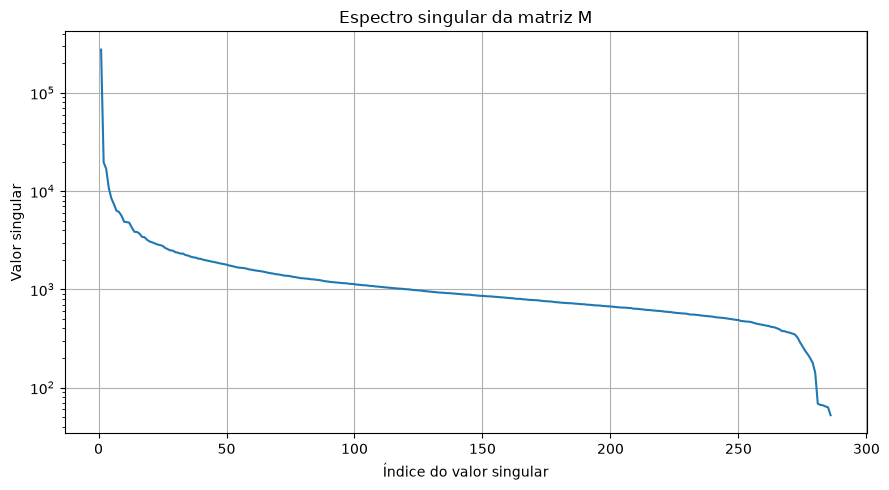

k =  1 | ||M - L_k||_F = 39408.2242 | Teórico = 39408.2242 | Erro relativo = 14.12%
k =  2 | ||M - L_k||_F = 34116.2918 | Teórico = 34116.2918 | Erro relativo = 12.22%
k =  3 | ||M - L_k||_F = 29667.3261 | Teórico = 29667.3261 | Erro relativo = 10.63%
k =  4 | ||M - L_k||_F = 27629.4695 | Teórico = 27629.4695 | Erro relativo = 9.90%
k =  5 | ||M - L_k||_F = 26298.0019 | Teórico = 26298.0019 | Erro relativo = 9.42%
k = 10 | ||M - L_k||_F = 22448.2125 | Teórico = 22448.2125 | Erro relativo = 8.04%
k = 20 | ||M - L_k||_F = 18788.7216 | Teórico = 18788.7216 | Erro relativo = 6.73%
k = 100 | ||M - L_k||_F = 9917.9439 | Teórico = 9917.9439 | Erro relativo = 3.55%

Energia acumulada para os postos analisados:
k =   1 | E(k) = 0.980066 (98.01%)
k =   2 | E(k) = 0.985060 (98.51%)
k =   3 | E(k) = 0.988703 (98.87%)
k =   4 | E(k) = 0.990201 (99.02%)
k =   5 | E(k) = 0.991123 (99.11%)
k =  10 | E(k) = 0.993532 (99.35%)
k =  20 | E(k) = 0.995469 (99.55%)
k = 100 | E(k) = 0.998737 (99.87%)


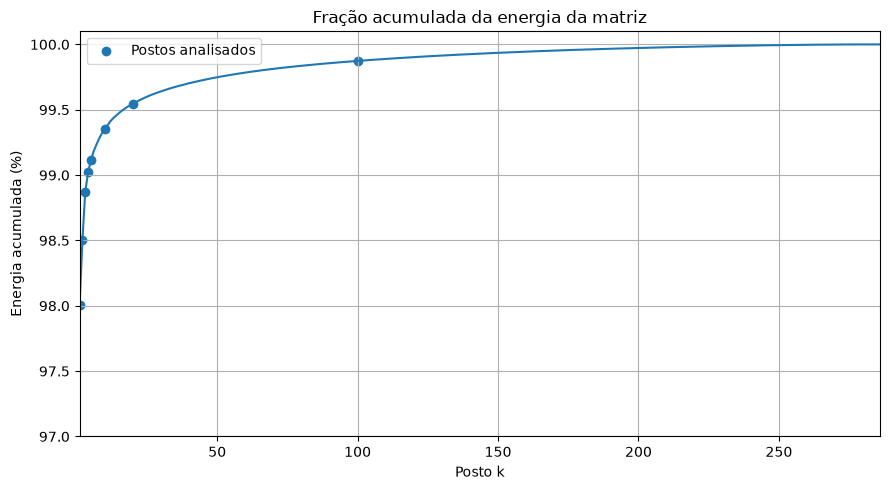

In [7]:
# Parte 3 APROXIMAÇÃO DE BAIXO POSTO 
def aproximacao_baixo_posto(U, S, Vt, k):
    # Calcula a aproximacao de posto no maximo k (Eq. 11):
    # Garante que os valores singulares estejam em um vetor 1D
    s = np.diag(S) if S.ndim == 2 else S
    r = len(s)

    if not (1 <= k <= r):
        raise ValueError(f"k deve estar entre 1 e {r}.")

    # Mantem apenas os k maiores valores singulares e seus vetores correspondentes
    U_k = U[:, :k]
    Sigma_k = np.diag(s[:k])
    Vt_k = Vt[:k, :]

    L_k = U_k @ Sigma_k @ Vt_k
    return L_k


def avaliar_aproximacao(M, L_k, s=None, k=None):
    """
    Calcula o erro na norma de Frobenius ||M - L_k||_F (Eq. 12)
    e o erro relativo percentual.
    """
    erro_frob = np.linalg.norm(M - L_k, ord='fro')
    norma_M = np.linalg.norm(M, ord='fro')
    erro_relativo = erro_frob / norma_M

    resultado = {
        "erro_frobenius": erro_frob,
        "erro_relativo": erro_relativo,
    }

    # Verificacao teorica: ||M - L_k||_F = sqrt(sum_{i=k+1}^r sigma_i^2)
    if s is not None and k is not None:
        s_vec = np.diag(s) if s.ndim == 2 else s
        resultado["erro_teorico_sigmas"] = np.sqrt(np.sum(s_vec[k:] ** 2))

    return resultado

# 1. Obter a matriz M do video
largura, altura = 160, 120
M = obter_matriz_M("data/caio_lutando.mp4", largura=largura, altura=altura)

# 2. Calcular a SVD reduzida de M (M = U @ diag(s) @ Vt)
U, s, Vt = np.linalg.svd(M, full_matrices=False)
r = len(s)
print(f"Dimensão de M: {M.shape} | Posto máximo r: {r}")

# 2.1 Gráfico do espectro singular
plt.figure(figsize=(9, 5))

plt.semilogy(np.arange(1, r + 1), s)

plt.xlabel("Índice do valor singular")
plt.ylabel("Valor singular")
plt.title("Espectro singular da matriz M")

plt.grid(True)
plt.tight_layout()
plt.show()

# 3. Testar diferentes valores de posto k <= r (arbitrarios)
valores_k = [1, 2, 3, 4, 5, 10, 20, 100]
valores_k = [k for k in valores_k if k <= r]

aproximacoes = {}
for k in valores_k:
    L_k = aproximacao_baixo_posto(U, s, Vt, k)
    metricas = avaliar_aproximacao(M, L_k, s=s, k=k)
    aproximacoes[k] = L_k

    print(
        f"k = {k:2d} | "
        f"||M - L_k||_F = {metricas['erro_frobenius']:.4f} | "
        f"Teórico = {metricas['erro_teorico_sigmas']:.4f} | "
        f"Erro relativo = {metricas['erro_relativo']*100:.2f}%"
    )

# 4. Energia acumulada dos valores singulares (Eq. 18 do relatorio)
# A energia e calculada para todos os postos, sem refazer a SVD.
energia_acumulada = np.cumsum(s**2) / np.sum(s**2)

print("\nEnergia acumulada para os postos analisados:")
for k in valores_k:
    print(f"k = {k:3d} | E(k) = {energia_acumulada[k-1]:.6f} "
          f"({100*energia_acumulada[k-1]:.2f}%)")

plt.figure(figsize=(9, 5))
plt.plot(np.arange(1, r+1), 100*energia_acumulada)
plt.scatter(valores_k, 100*energia_acumulada[np.array(valores_k)-1],
            label="Postos analisados")
plt.xlabel("Posto k")
plt.ylabel("Energia acumulada (%)")
plt.title("Fração acumulada da energia da matriz")
plt.xlim(1, r)
plt.ylim(97, 100.1)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


[1, 2, 3, 4, 5, 10, 20, 100]


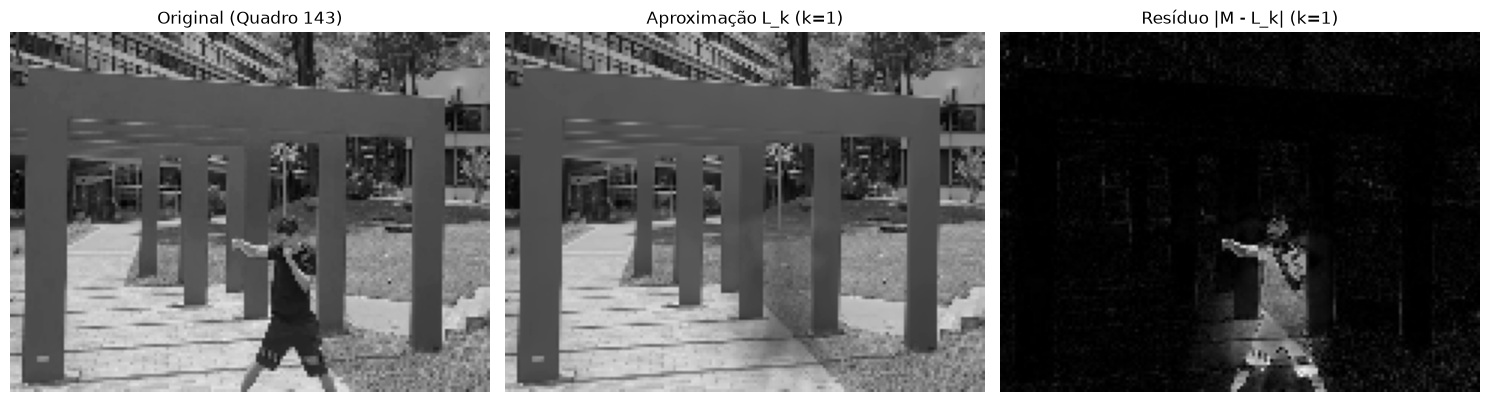

In [8]:
print(valores_k)

# Visualizacao dos quadros reconstruidos (Lk e do residuo (M - Lk))
idx_quadro = M.shape[1] // 2  # Quadro central do video (PRA TESTE)
k_escolhido = valores_k[0]    # Defina o k que deseja de 0 a 7 (1, 2, 3, 4, 5, 10, 20, 100) (PRA TESTE) (k=1, retira o que ta em movimento, k=100, mantem tudo)
L_k = aproximacoes[k_escolhido] # influencia no quao bom e o recorte 

quadro_original = M[:, idx_quadro].reshape((altura, largura))
quadro_Lk = np.clip(L_k[:, idx_quadro].reshape((altura, largura)), 0, 255)
quadro_residuo = np.abs(M[:, idx_quadro] - L_k[:, idx_quadro]).reshape((altura, largura))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].imshow(quadro_original, cmap='gray', vmin=0, vmax=255)
axes[0].set_title(f"Original (Quadro {idx_quadro})")
axes[0].axis('off')

axes[1].imshow(quadro_Lk, cmap='gray', vmin=0, vmax=255)
axes[1].set_title(f"Aproximação L_k (k={k_escolhido})")
axes[1].axis('off')

axes[2].imshow(quadro_residuo, cmap='gray')
axes[2].set_title(f"Resíduo |M - L_k| (k={k_escolhido})")
axes[2].axis('off')

plt.tight_layout()
plt.show()

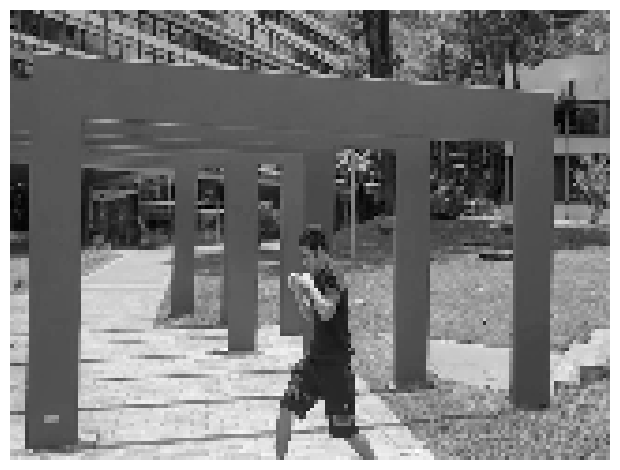

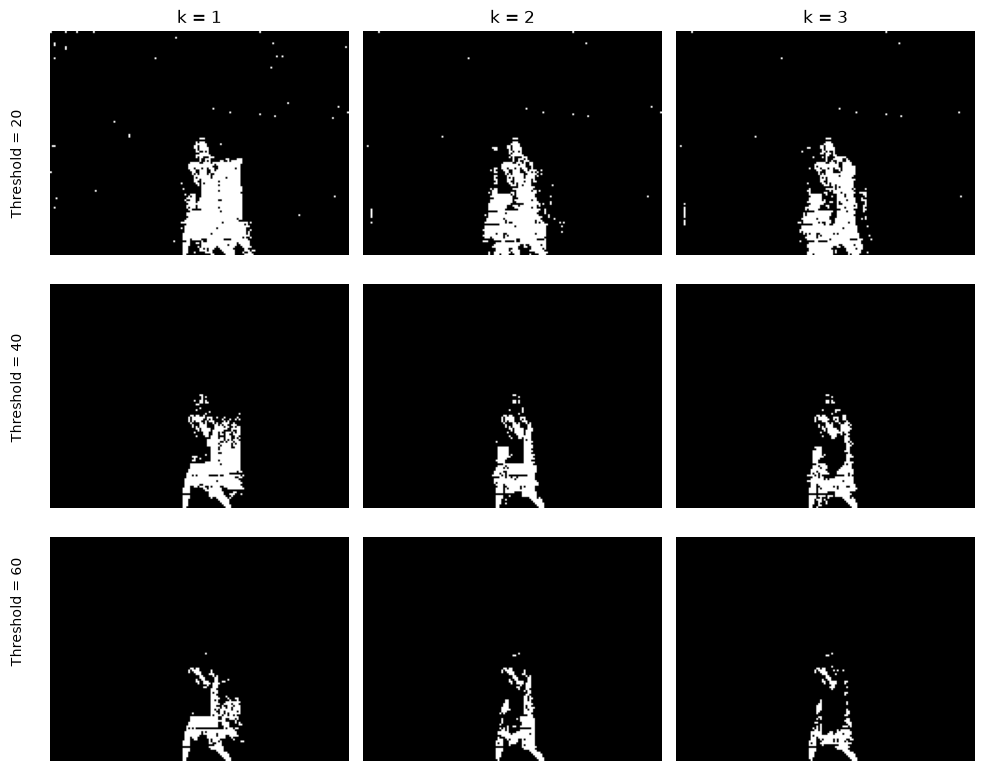

In [9]:
# Parte 4: Identificação de Movimento
# Caio Lucas Indalécio

def mat_res(M, L_k):
    R_k = M - L_k # Dada uma matriz e um L_k, calcula-se o resíduo R_k (movimento)
    S_k = np.abs(R_k) # S_k é uma matriz cujos elementos são o módulo dos elementos de R_k 
    return R_k, S_k

# Criando uma mascára binária
def mask(S_k, threshold):
    # Mask é uma matriz que transforma os valores acima de um limiar em 1 e abaixo ou igual em zero
    # Mask é, portanto, uma máscara binária.
    mask = (S_k > threshold).astype(np.uint8) 
    return mask


L_1 = aproximacoes[1]
L_2 = aproximacoes[2]
L_3 = aproximacoes[3]


R_1, S_1 = mat_res(M, L_1)
R_2, S_2 = mat_res(M, L_2)
R_3, S_3 = mat_res(M, L_3)

# Calculando a máscara para threshold = 20 nas máscaras 1, 2, 3
n_frame = 100
threshold = 20
mask_1 = mask(S_1, threshold)
mask_2 = mask(S_2, threshold)
mask_3 = mask(S_3, threshold)

frame_1 = mask_1[:, n_frame].reshape(120, 160)
frame_2 = mask_2[:, n_frame].reshape(120, 160)
frame_3 = mask_3[:, n_frame].reshape(120, 160)

# Calculando a máscara para threshold = 40 nas máscaras 1, 2, 3
threshold = 40
mask_1 = mask(S_1, threshold)
mask_2 = mask(S_2, threshold)
mask_3 = mask(S_3, threshold)

frame_4 = mask_1[:, n_frame].reshape(120, 160)
frame_5 = mask_2[:, n_frame].reshape(120, 160)
frame_6 = mask_3[:, n_frame].reshape(120, 160)

# Calculando a máscara para threshold = 60 nas máscaras 1, 2, 3
threshold = 60
mask_1 = mask(S_1, threshold)
mask_2 = mask(S_2, threshold)
mask_3 = mask(S_3, threshold)

frame_7 = mask_1[:, n_frame].reshape(120, 160)
frame_8 = mask_2[:, n_frame].reshape(120, 160)
frame_9 = mask_3[:, n_frame].reshape(120, 160)

# Frame original
frame_orig = M[:,n_frame].reshape(120, 160)

# Plotar Frame Original
plt.imshow(frame_orig, cmap='gray')
plt.axis('off')
plt.tight_layout()
plt.show()

# Plotar Máscaras
fig, ax = plt.subplots(3, 3, figsize=(10, 8))

# Threshold = 20
ax[0, 0].imshow(frame_1, cmap='gray')
ax[0, 1].imshow(frame_2, cmap='gray')
ax[0, 2].imshow(frame_3, cmap='gray')

# Threshold = 40
ax[1, 0].imshow(frame_4, cmap='gray')
ax[1, 1].imshow(frame_5, cmap='gray')
ax[1, 2].imshow(frame_6, cmap='gray')

# Threshold = 60
ax[2, 0].imshow(frame_7, cmap='gray')
ax[2, 1].imshow(frame_8, cmap='gray')
ax[2, 2].imshow(frame_9, cmap='gray')

# Identificação das colunas e linhas
for j, k in enumerate([1, 2, 3]):
    ax[0, j].set_title(f'k = {k}')

for i, threshold in enumerate([20, 40, 60]):
    ax[i, 0].set_ylabel(f'Threshold = {threshold}')

# Removendo os eixos
for a in ax.flat:
    a.axis('off')

plt.tight_layout()
fig.text(0.02, 0.78, 'Threshold = 20', rotation=90, va='center')
fig.text(0.02, 0.50, 'Threshold = 40', rotation=90, va='center')
fig.text(0.02, 0.22, 'Threshold = 60', rotation=90, va='center')
plt.subplots_adjust(left=0.06)
plt.show()


### Comentario sobre as análises dos threshold
Nota-se que quanto maior o threshold, menos elementos da matriz S são considerados como 1 na matriz mask, assim, menos partes do vídeo são consideradas em movimento, apagando a imagem.
Além disso, quanto maior o k, melhor é a aproximação da matriz M, diminuindo assim as áreas que são consideradas em movimento.

In [10]:
# Parte 5: Reconstrução do vídeo
# Luiz Gustavo Borges e Cunha - Rizzioli não fez nada

def recontruir_video(M, L_k, S_k, caminho_original, caminho_saida,
                     largura_matriz=160, altura_matriz=120):
    """Gera um vídeo lado a lado: original, fundo aproximado e movimento."""
    captura = cv2.VideoCapture(caminho_original)
    if not captura.isOpened():
        raise ValueError("Não foi possível abrir o vídeo original.")

    largura = int(captura.get(cv2.CAP_PROP_FRAME_WIDTH))
    altura = int(captura.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = captura.get(cv2.CAP_PROP_FPS)

    if L_k.shape != M.shape or S_k.shape != M.shape:
        captura.release()
        raise ValueError("M, L_k e S_k devem ter as mesmas dimensões.")

    codec = cv2.VideoWriter_fourcc(*"mp4v")
    video = cv2.VideoWriter(caminho_saida, codec, fps, (3 * largura, altura))
    if not video.isOpened():
        captura.release()
        raise ValueError("Não foi possível criar o vídeo de saída.")

    try:
        for i in range(M.shape[1]):
            ret, original = captura.read()
            if not ret:
                raise ValueError("O vídeo original tem menos quadros que M.")

            fundo = L_k[:, i].reshape((altura_matriz, largura_matriz))
            fundo = np.clip(fundo, 0, 255).astype(np.uint8)
            fundo = cv2.resize(fundo, (largura, altura))
            fundo = cv2.cvtColor(fundo, cv2.COLOR_GRAY2BGR)

            movimento = S_k[:, i].reshape((altura_matriz, largura_matriz))
            mascara = mask(movimento, 40) * 255
            mascara = cv2.resize(
                mascara, (largura, altura), interpolation=cv2.INTER_NEAREST
            )
            regioes_movimento = cv2.bitwise_and(
                original, original, mask=mascara
            )

            # Cada quadro de saída reúne os três painéis na ordem do projeto.
            video.write(np.hstack((original, fundo, regioes_movimento)))
    finally:
        captura.release()
        video.release()

    print(f"Vídeo comparativo salvo em: {caminho_saida}")

# Calcula o resíduo e as regiões de movimento para o posto escolhido.
R_k, S_k = mat_res(M, L_k)
'''recontruir_video(
    M, L_k, S_k, "data/caio_lutando.mp4", "data/video_reconstruido.avi",
    largura_matriz=largura, altura_matriz=altura
)'''



'recontruir_video(\n    M, L_k, S_k, "data/caio_lutando.mp4", "data/video_reconstruido.avi",\n    largura_matriz=largura, altura_matriz=altura\n)'

In [11]:
#Código principal:

#Tratamento do vídeo, tranformando-o em matriz
pegar_informacoes("data/caio_lutando.mp4") #Começando extraindo informações do vídeo original
M = obter_matriz_M("data/caio_lutando.mp4") #Usando a função criada para obter a matriz M

#Cálculo da SVD
U_r, Sigma_r, V_r, tempo_jacobi = DecomposicaoSVD_Jacobi(M)
erro_reconstrucao = np.linalg.norm(M - U_r @ Sigma_r @ V_r.T, ord="fro")
print("\nJacobi: Dimensoes de U_r, Sigma_r e V_r:", U_r.shape, Sigma_r.shape, V_r.shape)
print("Erro de reconstrucao:", erro_reconstrucao)
print("Tempo de execucao do metodo de Jacobi:", tempo_jacobi, "segundos\n")
u, s, v = np.linalg.svd(M) #rotina pronta de SVD

#Aproximação de baixo posto
L_k = aproximacao_baixo_posto(u, s, v, 1)

#Identificação do movimento
R_k, S_k = mat_res(M, L_k)

#Recontrução do vídeo
recontruir_video(M, L_k, S_k, "data/caio_lutando.mp4", "data/video_reconstruido.mp4",largura_matriz=largura, altura_matriz=altura)




FPS: 30.0
Duração: 9.533333333333333 segundos
Resolução: 1920x1080
Pixels por quadro: 2073600
Total de quadros: 286
Total de pixels no vídeo: 593049600

Jacobi: Dimensoes de U_r, Sigma_r e V_r: (19200, 286) (286, 286) (286, 286)
Erro de reconstrucao: 9.639357465865356e-09
Tempo de execucao do metodo de Jacobi: 41.554334597000036 segundos

Vídeo comparativo salvo em: data/video_reconstruido.mp4
